In [1]:
import os
import numpy as np
import pandas as pd
import scanpy as sc
from pygam import LinearGAM, s
import matplotlib.pyplot as plt

In [2]:
pth = os.path.join('..', '..', '..', '..')
pth_data = os.path.join(pth, 'data')
pth_in = os.path.join(pth_data, 'cancer', 'human', 'transitions', 'SK-N-SH')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_out = os.path.join(pth, 'figures', 'cancer', 'human', 'transitions', 'SK-N-SH')

In [3]:
adata = sc.read_h5ad(os.path.join(pth_in, 'trajectory.h5ad'))
adata

AnnData object with n_obs × n_vars = 8442 × 27739
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'percent.mt', 'percent.RPL', 'percent.RPS', 'S.Score', 'G2M.Score', 'Phase', 'CC.Difference', 'nCount_SCT', 'nFeature_SCT', 'SCT_snn_res.0.8', 'seurat_clusters', 'myOrig.ident', 'myOrig.ident2', 'Timepoint', 'ident', 'leiden', 'celltype', 't', 'seg', 'edge', 'milestones'
    var: 'n_cells', 'm', 'v', 'n_obs', 'res', 'lp', 'lpa', 'qv', 'highly_variable'
    uns: 'Timepoint_colors', 'X_name', 'celltype_colors', 'graph', 'leiden', 'leiden_colors', 'log1p', 'milestones_colors', 'neighbors', 'pca', 'pseudotime_list', 'seg_colors', 'umap'
    obsm: 'PCA', 'UMAP', 'X_R', 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    layers: 'logcounts'
    obsp: 'connectivities', 'distances'

In [4]:
g = pd.read_csv(os.path.join(pth_feat, 'union.csv')).hsapiens.drop_duplicates()
g = g.loc[g.isin(adata.var_names)].reset_index(drop = True)

In [6]:
def fit_gam(Y, X, n_spl, n_pts):
    GAM = LinearGAM(s(0, n_splines = n_spl))
    GAM = GAM.fit(X, scale_01(Y))
    xx = np.linspace(X.min(), X.max(), n_pts)
    return scale_01(GAM.predict(xx))

def scale_01(Y):
    return (Y - Y.min()) / (Y.max() - Y.min())

In [7]:
# fit GAMs (features)
n_pts, n_spl = 500, 5
X = np.zeros((g.size, n_pts))
t = adata.obs.t.values.copy()
for i, name in g.items():
    Y = adata[:, name].X.toarray()
    if np.unique(Y).size > 1:
        X[i] = fit_gam(Y, t, n_spl, n_pts)

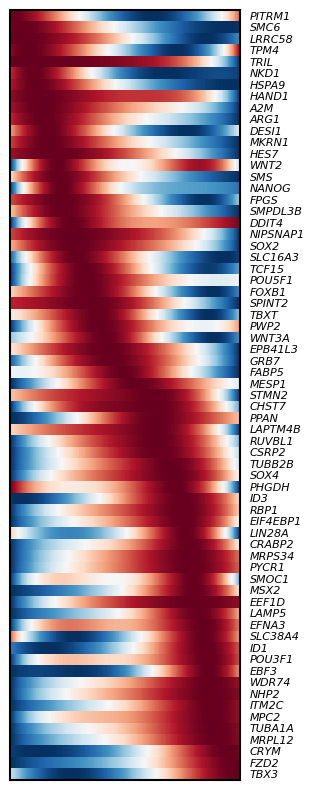

In [10]:
# select, order features
ixmax = X.argmax(axis = 1)
msk = (ixmax > 0) & (ixmax < (n_pts - 1))
order = ixmax[msk].argsort()
X_plt = X[msk][order].copy()

# plot heatmap
fig, ax = plt.subplots(1, 1, figsize = (10, 10))
ax.imshow(X_plt, aspect = 25, interpolation = 'nearest', cmap = 'RdBu_r')
yticks, yticklabels = np.arange(X_plt.shape[0]), g.loc[msk].iloc[order].copy()
ax.set_yticks(yticks, yticklabels, fontsize = 8, fontstyle = 'italic')
ax.tick_params('y', left = False, labelleft = False, labelright = True)
ax.set_xticks([])
for sp in ax.spines.values(): sp.set_linewidth(1.5)
fn = os.path.join(pth_out, 'features.pdf')
plt.savefig(fn, bbox_inches = 'tight')

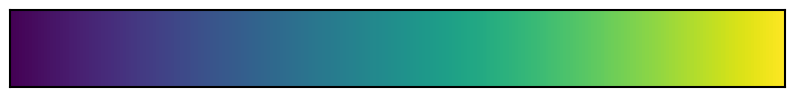

In [23]:
# plot pseudotime
fig, ax = plt.subplots(1, 1, figsize = (10, 10))
xx = np.linspace(t.min(), t.max(), n_pts).reshape(1, -1)
ax.imshow(xx, aspect = 50, interpolation = 'nearest', cmap = 'viridis')
ax.set_yticks([]); ax.set_xticks([])
for sp in ax.spines.values(): sp.set_linewidth(1.5)
fn = os.path.join(pth_out, 'pseudotime.pdf')
plt.savefig(fn, bbox_inches = 'tight')